### Employee Absenteeism Dataset

Problem Statement :- This dataset allows predicting of Absenteeism time in hours of employees at work. 



In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="ticks", color_codes=True)
#import warnings
#warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
absentism_data =  pd.read_excel(r'C:\Users\Dad\Documents\Data Tales\Employee Absentism\Absenteeism_at_work.xls', trim_ws = True)

'trim_ws' attribute :- Should leading or trailing whitespace be trimmed from each field before parsing it?

In [3]:
# Glance at the data
pd.set_option('display.max_columns',30)
absentism_data.head(5)

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,Hit target,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239554,97,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239554,97,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239554,97,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239554,97,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239554,97,0,1,2,1,0,1,90,172,30,2


In [4]:
# Know the data types of all the variables of the dataset
absentism_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 21 columns):
ID                                 740 non-null int64
Reason for absence                 740 non-null int64
Month of absence                   740 non-null int64
Day of the week                    740 non-null int64
Seasons                            740 non-null int64
Transportation expense             740 non-null int64
Distance from Residence to Work    740 non-null int64
Service time                       740 non-null int64
Age                                740 non-null int64
Work load Average/day              740 non-null int64
Hit target                         740 non-null int64
Disciplinary failure               740 non-null int64
Education                          740 non-null int64
Son                                740 non-null int64
Social drinker                     740 non-null int64
Social smoker                      740 non-null int64
Pet                            

#### Description of features :-


1. ID: Individual identification (ID) 
2. Reason for absence: Absences attested by the International Code of Diseases (ICD) stratified into 21 categories (I to XXI) as follows: 
<ul>
<li>I Certain infectious and parasitic diseases</li>
<li>II Neoplasms</li>
<li>III Diseases of the blood and blood-forming organs and certain disorders involving the immune mechanism</li> 
<li>IV Endocrine, nutritional and metabolic diseases</li>
<li>V Mental and behavioural disorders</li>
<li>VI Diseases of the nervous system</li>
<li>VII Diseases of the eye and adnexa</li>
<li>VIII Diseases of the ear and mastoid process</li>
<li>IX Diseases of the circulatory system</li>
<li>X Diseases of the respiratory system</li>
<li>XI Diseases of the digestive system</li>
<li>XII Diseases of the skin and subcutaneous tissue</li>
<li>XIII Diseases of the musculoskeletal system and connective tissue</li>
<li>XIV Diseases of the genitourinary system</li>
<li>XV Pregnancy, childbirth and the puerperium</li>
<li>XVI Certain conditions originating in the perinatal period</li> 
<li>XVII Congenital malformations, deformations and chromosomal abnormalities</li>
<li>XVIII Symptoms, signs and abnormal clinical and laboratory findings, not elsewhere classified</li> 
<li>XIX Injury, poisoning and certain other consequences of external causes</li>
<li>XX External causes of morbidity and mortality</li>
<li>XXI Factors influencing health status and contact with health services.</li> 

And 7 categories without (CID) patient follow-up (22), medical consultation (23), blood donation (24), laboratory examination (25), unjustified absence (26), physiotherapy (27), dental consultation (28). 

3. Month of absence 
4. Day of the week ( Saturday(0), Sunday(1), Monday (2), Tuesday (3), Wednesday (4), Thursday (5), Friday (6)) 
5. Seasons (summer (1), autumn (2), winter (3), spring (4)) 
6. Transportation expense 
7. Distance from Residence to Work (kilometers) 
8. Service time 
9. Age 
10. Work load Average/day 
11. Hit target 
12. Disciplinary failure (yes=1; no=0) 
13. Education (high school (1), graduate (2), postgraduate (3), master and doctor (4)) 
14. Son (number of children) 
15. Social drinker (yes=1; no=0) 
16. Social smoker (yes=1; no=0) 
17. Pet (number of pet) 
18. Weight 
19. Height 
20. Body mass index 
21. Absenteeism time in hours (target) 



In [5]:
# Renaming Columns
absentism_data.columns = ['ID', 'Reason_for_absence', 'Month_of_absence', 'Day_of_the_week',
       'Seasons', 'Transportation_expense','Distance_from_Residence_to_Work', 'Service_time', 'Age',
       'Work_load_Average_day', 'Hit_target', 'Disciplinary_failure','Education', 'Son', 'Social_drinker', 'Social_smoker', 'Pet',
       'Weight', 'Height', 'Body_mass_index', 'Absenteeism_time_in_hours']

In [6]:
absentism_data.Work_load_Average_day.value_counts()

222196    36
264249    33
237656    32
343253    29
265017    28
284853    25
308593    24
268519    23
284031    22
244387    22
241476    22
205917    21
251818    21
326452    20
246288    20
230290    20
236629    19
275089    19
239554    19
253957    19
294217    19
306345    18
253465    18
302585    18
265615    18
378884    16
246074    16
377550    16
275312    16
313532    15
261306    15
280549    15
249797    15
239409    13
261756    12
264604    12
330061    11
271219     3
Name: Work_load_Average_day, dtype: int64

In [7]:
# Removing Observations with 'Absenteeism time in hours' equal to zero
absentism = absentism_data.loc[absentism_data['Absenteeism_time_in_hours']!= 0,:]
absentism.shape

(696, 21)

In [8]:
# Let us see how many obeservations are being dropped
(absentism_data.shape[0] - absentism.shape[0]) / len(absentism_data) * 100

5.9459459459459465

We can see that 44 observations contain 'Absenteeism_time_in_hours' which comes up to 5.94%.

In [9]:
absentism.head()

,ID,Reason_for_absence,Month_of_absence,Day_of_the_week,Seasons,Transportation_expense,Distance_from_Residence_to_Work,Service_time,Age,Work_load_Average_day,Hit_target,Disciplinary_failure,Education,Son,Social_drinker,Social_smoker,Pet,Weight,Height,Body_mass_index,Absenteeism_time_in_hours
0,11,26,7,3,1,289,36,13,33,239554,97,0,1,2,1,0,1,90,172,30,4
2,3,23,7,4,1,179,51,18,38,239554,97,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239554,97,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239554,97,0,1,2,1,0,1,90,172,30,2
5,3,23,7,6,1,179,51,18,38,239554,97,0,1,0,1,0,0,89,170,31,2


In [10]:
type(absentism)

pandas.core.frame.DataFrame

#### Missing values 

Checking the missing values in the dataframe 'absentism' by finding the % of missing values of each column.

In [11]:
absentism.isna().sum()
Missing_Value = pd.DataFrame((absentism.isna().sum()/len(absentism_data)*100))

Missing_Value.reset_index()
Missing_Value = Missing_Value.rename(columns = {'index': 'Variables', 0: 'Missing_percentage'})
#Arranging Missing Values in Decreasing Order
Missing_Value = Missing_Value.sort_values('Missing_percentage', ascending = False)
Missing_Value

,Missing_percentage
ID,0.0
Disciplinary_failure,0.0
Body_mass_index,0.0
Height,0.0
Weight,0.0
Pet,0.0
Social_smoker,0.0
Social_drinker,0.0
Son,0.0
Education,0.0


In [12]:
# Size of the dataframe
absentism_data.shape

(740, 21)

### Outlier Analysis for Continous variables

Outliers in a dataset are just like a weeds of a plant. How the weeds hinder the growth in a plant, similarly outliers create noise in the dataset.

In [13]:
cont_names = ['Weight','Distance_from_Residence_to_Work','Service_time','Transportation_expense','Work_load_Average_day','Absenteeism_time_in_hours','Height','Body_mass_index','Age','Hit_target']

In [14]:
def visualize_box_plot(df,cols):
    n = 0
    this = []
    n_rows = 5
    n_cols = 2
    width  = 20
    height = 20
    
    for column in df[cols]:
        this.append(column)
        
    
    fig, ax = plt.subplots(n_rows, n_cols, sharex=False, sharey=False, figsize=(width, height))
    for row in range(n_rows):
        for col in range(n_cols):
            g = sns.boxplot(df[this[n]], ax = ax[row][col], color='white')
            
            ax[row,col].set_title("Column Name: {}".format(this[n]))
            ax[row,col].set_xlabel("")
            ax[row,col].set_ylabel("")
            n += 1
    plt.show()
    return
                     

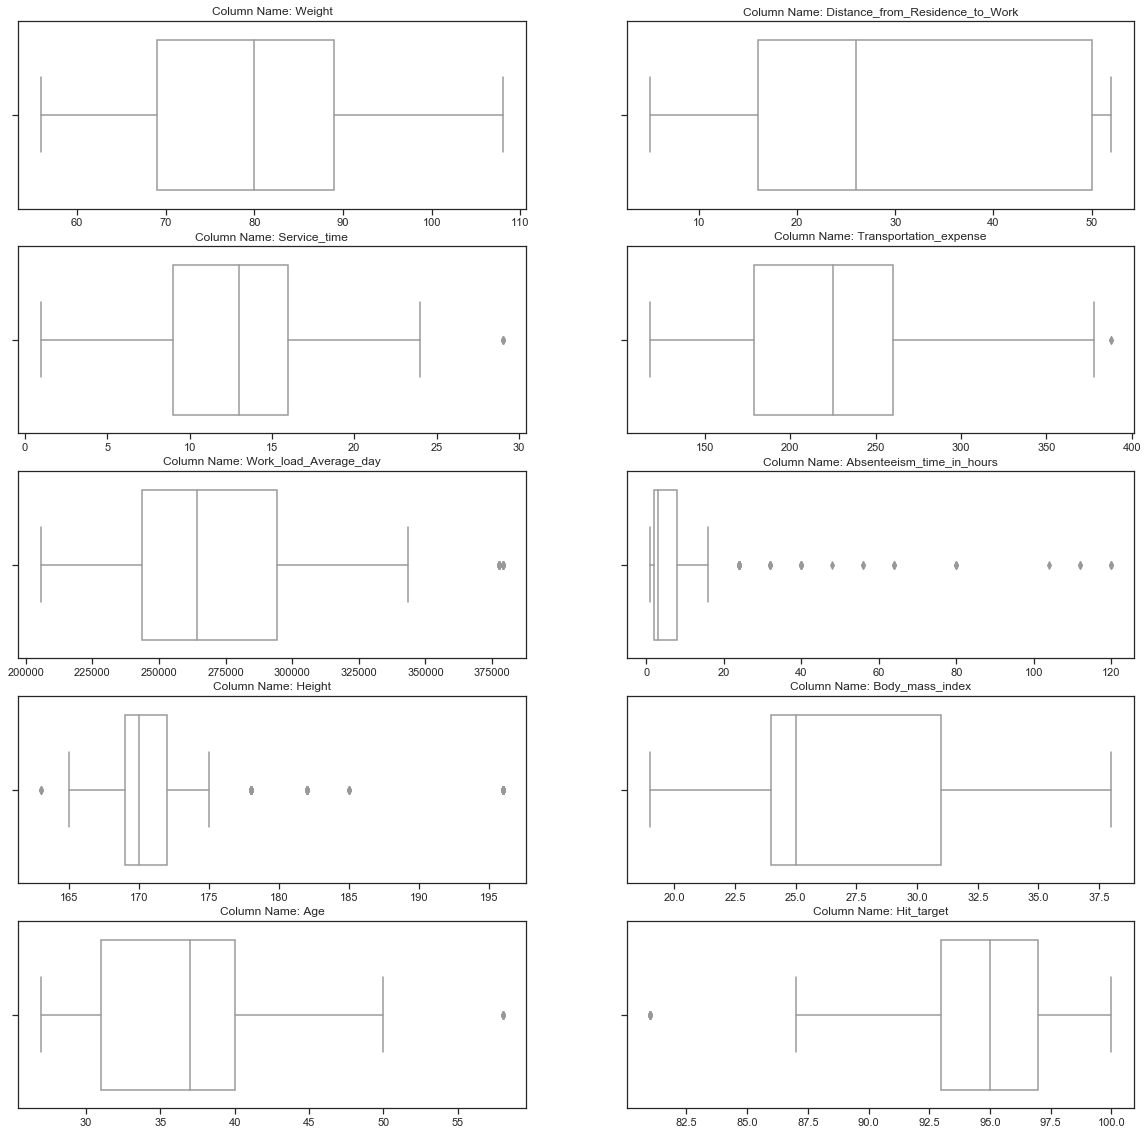

In [15]:
visualize_box_plot(absentism , cont_names)

#### Finding out outliers through Inter-Quartile Range(IQR) method.

We need to find out the first Quartile(25%) and the third quartile(75%) and get the range of values. The values which are below or above it are treated as 'Outliers'.

In [16]:
for i in cont_names:
    q75, q25 = np.percentile(absentism_data.loc[:,i], [75,25])
    iqr = q75 - q25
    minn = q25 - (iqr*1.5)
    maxx = q75 + (iqr*1.5)
    print("Min value : ",minn)
    print("Max value : ",maxx)
    print(" ")
    print('{var}---->{X} Outliers'.format(var = i, X = (absentism_data.loc[absentism_data.loc[:,i] < minn, i].count() + absentism_data.loc[absentism_data.loc[:,i] > maxx,i].count())))
    
                                                                           
                                                                           

Min value :  39.0
Max value :  119.0
 
Weight---->0 Outliers
Min value :  -35.0
Max value :  101.0
 
Distance_from_Residence_to_Work---->0 Outliers
Min value :  -1.5
Max value :  26.5
 
Service_time---->5 Outliers
Min value :  57.5
Max value :  381.5
 
Transportation_expense---->3 Outliers
Min value :  169642.0
Max value :  368962.0
 
Work_load_Average_day---->32 Outliers
Min value :  -7.0
Max value :  17.0
 
Absenteeism_time_in_hours---->44 Outliers
Min value :  164.5
Max value :  176.5
 
Height---->119 Outliers
Min value :  13.5
Max value :  41.5
 
Body_mass_index---->0 Outliers
Min value :  17.5
Max value :  53.5
 
Age---->8 Outliers
Min value :  87.0
Max value :  103.0
 
Hit_target---->19 Outliers


Outliers consists of 54.4% of data. On removing outliers it may cause data reduction. So this method is not preferred.

After Data Cleaning stage, we will move ahead to data preprocessing step and explore the insights of the variables and find out the relationship among the target and other variables.

### Data Preprocessing

### Continuous Variables Distributions

In [17]:
def visualize_plot(df,cols):
    n = 0
    this = []
    n_rows = 5
    n_cols = 2
    width  = 20
    height = 20
    
    for column in df[cols]:
        this.append(column)
        
    
    fig, ax = plt.subplots(n_rows, n_cols, sharex=False, sharey=False, figsize=(width, height))
    for row in range(n_rows):
        for col in range(n_cols):
            g = sns.distplot(df[this[n]], ax = ax[row][col])
            
            ax[row,col].set_title("Column Name: {}".format(this[n]))
            ax[row,col].set_xlabel("")
            ax[row,col].set_ylabel("")
            n += 1
    plt.show()
    return

C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


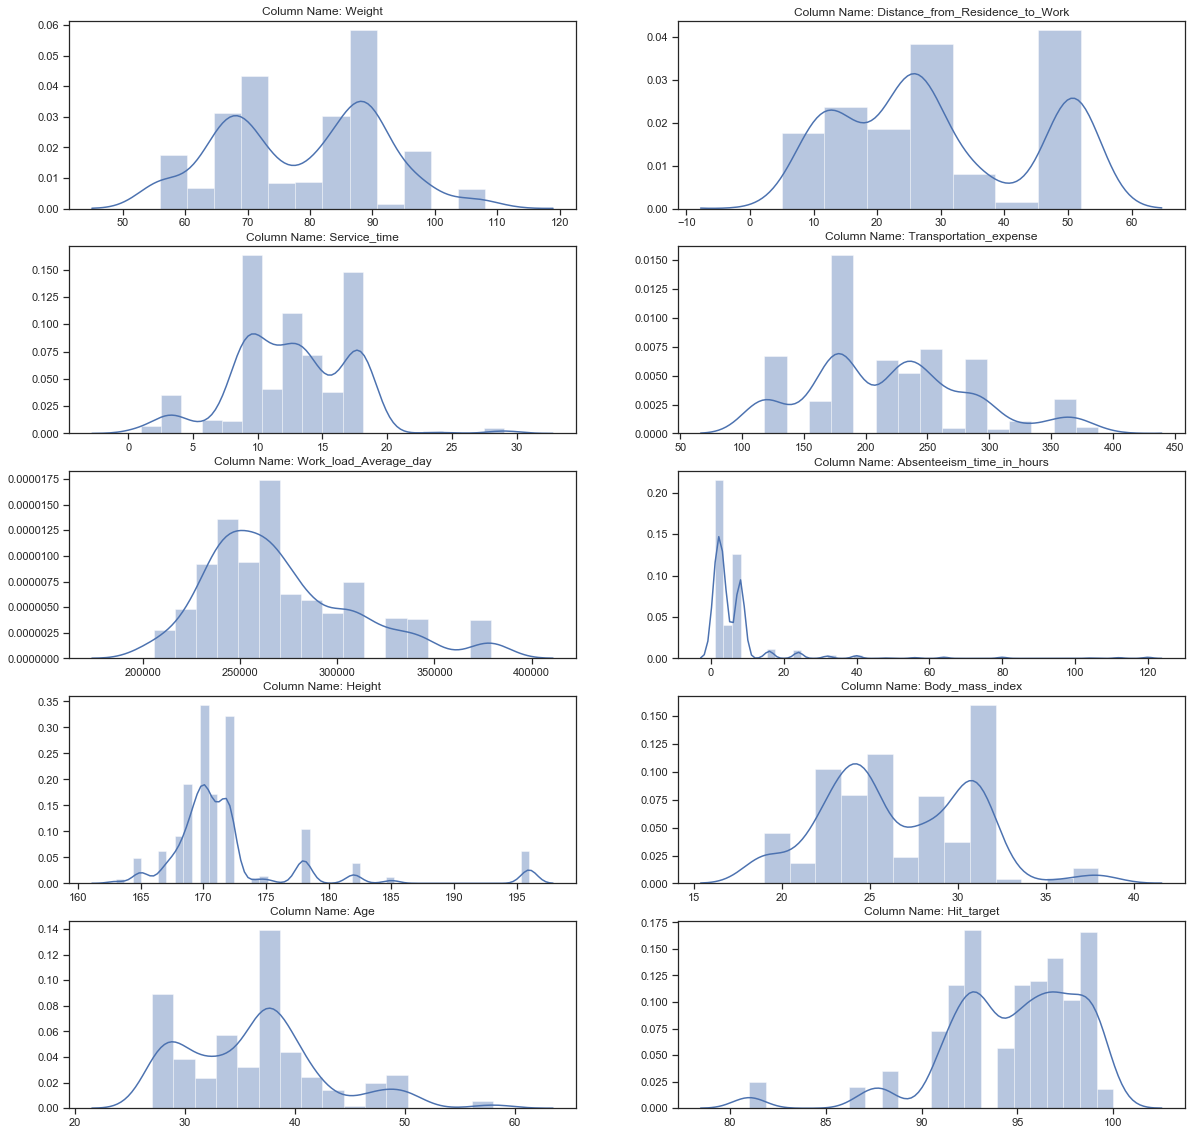

In [18]:
visualize_plot(absentism,cont_names)

We can observe from the figures that data follows skewed distribution.

### Statistical Analysis

#### Chi-Square Test

Chi-Square Test is used in testing null hypothesis. For Chi-Square Test, we make use of categorical variables.

In [19]:
catnames = ['Day_of_the_week','Seasons','Month_of_absence','Social_drinker','Reason_for_absence','Social_smoker','Pet','Son',
'Disciplinary_failure','Education']

In [20]:
from scipy.stats import chi2_contingency

In [21]:
factors_paired = [(i,j) for i in catnames for j in catnames] 
chi2, p_values =[], []
for f in factors_paired:
    if f[0] != f[1]:
        chitest = chi2_contingency(pd.crosstab(absentism[f[0]], absentism[f[1]]))
        chi2.append(chitest[0])
        p_values.append(chitest[1])
    else:
        chi2.append(0)
        p_values.append(0)

p1 = np.array(p_values).reshape((10,10))
p1 = pd.DataFrame(p1, index=catnames, columns=catnames)
p1

,Day_of_the_week,Seasons,Month_of_absence,Social_drinker,Reason_for_absence,Social_smoker,Pet,Son,Disciplinary_failure,Education
Day_of_the_week,0.000000e+00,4.086874e-01,6.765307e-01,3.040911e-01,5.170971e-02,5.388357e-01,4.012904e-01,1.889736e-09,1.0,6.369421e-01
Seasons,4.086874e-01,0.000000e+00,0.000000e+00,1.473154e-01,6.493726e-19,6.615252e-02,1.090705e-04,1.795308e-05,1.0,8.936680e-02
Month_of_absence,6.765307e-01,0.000000e+00,0.000000e+00,3.040382e-02,2.191275e-14,1.838631e-02,6.376062e-05,4.226723e-05,1.0,8.873931e-03
Social_drinker,3.040911e-01,1.473154e-01,3.040382e-02,0.000000e+00,2.253390e-08,1.031400e-02,1.303426e-26,4.393599e-09,1.0,1.426601e-33
Reason_for_absence,5.170971e-02,6.493726e-19,2.191275e-14,2.253390e-08,0.000000e+00,1.742354e-09,1.386394e-18,1.788850e-19,1.0,1.895058e-10
Social_smoker,5.388357e-01,6.615252e-02,1.838631e-02,1.031400e-02,1.742354e-09,0.000000e+00,6.587414e-14,2.868110e-20,1.0,5.635243e-26
Pet,4.012904e-01,1.090705e-04,6.376062e-05,1.303426e-26,1.386394e-18,6.587414e-14,0.000000e+00,8.122222e-90,1.0,3.323522e-29
Son,1.889736e-09,1.795308e-05,4.226723e-05,4.393599e-09,1.788850e-19,2.868110e-20,8.122222e-90,0.000000e+00,1.0,8.888863e-12
Disciplinary_failure,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.0,1.000000e+00
Education,6.369421e-01,8.936680e-02,8.873931e-03,1.426601e-33,1.895058e-10,5.635243e-26,3.323522e-29,8.888863e-12,1.0,0.000000e+00


#### Observations from above Contigency Table:-

1. From the above contigency table, we can state that features being independent to each other is a "Null Hypothesis" and if it is dependent to each other an "Alternate Hypothesis".

2. The Level of Significance is in the range(0.01 to 0.05). The features 'Seasons' ,'Reason_for_absence','Pet','Son' and 'Education' fall in the Rejection Region as their Level of significance doesn't belong to the range.

3. Inorder to find out the critical value , we need to find out the degrees of freedom = (noofrows - 1) * (noofcols - 1)
i.e ( 10 - 1) * ( 10 -1 ) = 81 and the critical value comes up to 61.261. 

4. Thus, the critical value obtained is 61.261. This is the value that the test-statistic must exceed inorder to the null hypothesis to get rejected i.e the absolute value of t-statistic must be 61.261 or greater.

### Correlation Analysis

Inorder to find correlation among the continuous variables we find the correlation among them using a heatmap.

In [22]:
absentism.shape

(696, 21)

In [23]:
corr = absentism[absentism.columns].corr()
corr.head()

,ID,Reason_for_absence,Month_of_absence,Day_of_the_week,Seasons,Transportation_expense,Distance_from_Residence_to_Work,Service_time,Age,Work_load_Average_day,Hit_target,Disciplinary_failure,Education,Son,Social_drinker,Social_smoker,Pet,Weight,Height,Body_mass_index,Absenteeism_time_in_hours
ID,1.000000,-0.082239,0.001350,0.037993,0.098344,-0.218650,-0.513676,-0.293064,0.025402,0.106659,0.007767,NaN,-0.031055,0.010626,-0.469789,0.002811,-0.022132,-0.261251,0.046235,-0.303154,-0.017577
Reason_for_absence,-0.082239,1.000000,-0.051632,0.139780,-0.049309,-0.082326,0.166834,0.063563,-0.012952,-0.135910,0.011565,NaN,-0.102716,-0.015184,0.121221,-0.071135,-0.029914,0.061504,-0.106396,0.116443,-0.300813
Month_of_absence,0.001350,-0.051632,1.000000,-0.004435,0.396522,0.130296,-0.005061,-0.060860,0.003033,-0.173712,-0.458745,NaN,-0.059851,0.071349,0.042514,-0.049586,0.074547,0.019309,-0.069368,0.047585,0.033875
Day_of_the_week,0.037993,0.139780,-0.004435,1.000000,0.049012,0.035570,0.118194,0.006891,-0.012138,0.018928,0.035371,NaN,0.059631,0.103492,0.038277,0.026839,-0.014858,-0.150461,-0.085867,-0.125316,-0.130839
Seasons,0.098344,-0.049309,0.396522,0.049012,1.000000,0.018140,-0.055463,-0.006818,-0.026869,0.164882,-0.047721,NaN,0.005660,0.039101,-0.050597,-0.080228,0.021174,-0.035183,-0.038188,-0.017491,0.012429


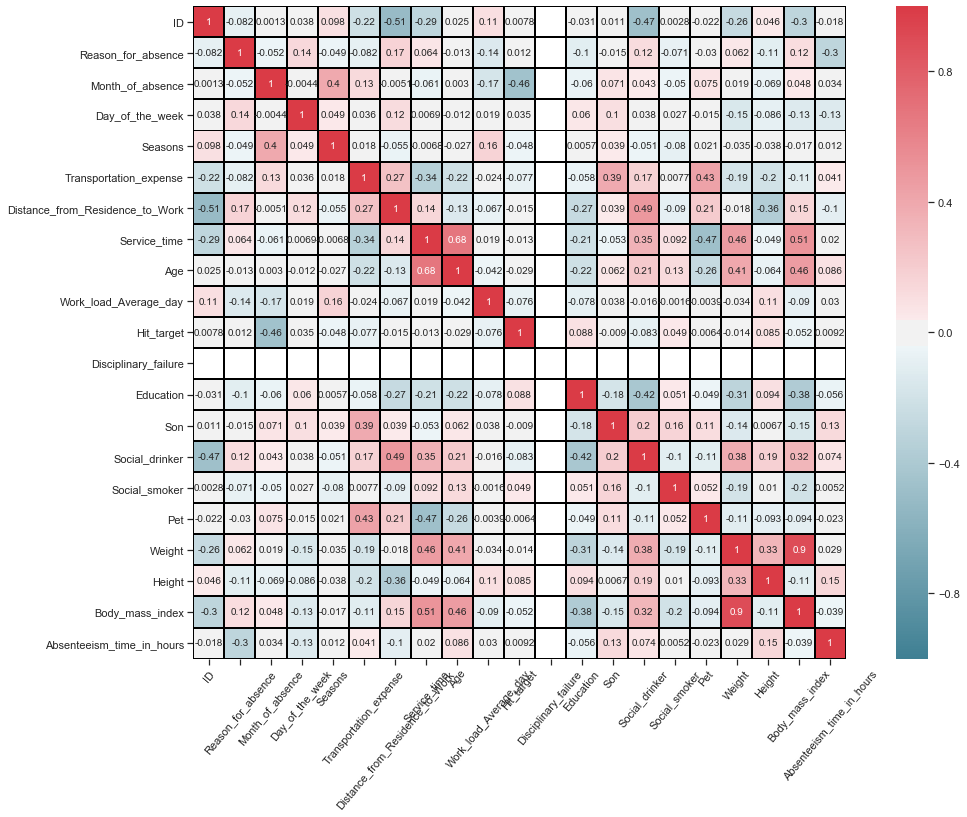

In [24]:
# correlation map
#Setting up the pane or matrix size
f, ax = plt.subplots(figsize=(18,12))  #Width,height

#Generating Corelation Matrix
corr = absentism[absentism.columns].corr()

#Plot using Seaborn library
sns.heatmap(corr,mask=np.zeros_like(corr, dtype=np.bool), cmap=sns.diverging_palette(220,10, as_cmap=True),\
            square=True, ax=ax,annot=True,linewidths=1 , linecolor= 'black',vmin = -1, vmax = 1)
sns.set(font_scale=1.8)
plt.xticks(rotation=50)
plt.show()
#f.savefig('heatmap.png')


Correlation test for continuous independent variables

No two variables have correlation coeff. > 0.95 so we will not drop any continuous independent variables.

#### Relationships of categorical independent variables with dependent variable


1. 'Reason_for_absence' Vs 'Absenteeism_time_in_hours'

In [25]:
def relationship(a,b):
    df = absentism_data.groupby(a)[b].sum().reset_index()
    df[b] = (df[b]*100)/sum(absentism_data[b])
    df = df.sort_values(by='Absenteeism_time_in_hours')
    print(df)
    return df.plot.barh(x=a,y=b, figsize = (12,10))

    Reason_for_absence  Absenteeism_time_in_hours
0                    0                   0.000000
16                  16                   0.117096
17                  17                   0.156128
3                    3                   0.156128
4                    4                   0.175644
15                  15                   0.312256
5                    5                   0.370804
23                  24                   0.468384
2                    2                   0.468384
8                    8                   0.624512
20                  21                   0.683060
24                  25                   2.107728
7                    7                   2.927400
26                  27                   3.064012
14                  14                   3.259173
9                    9                   3.278689
6                    6                   3.337237
1                    1                   3.551913
12                  12                   3.649493


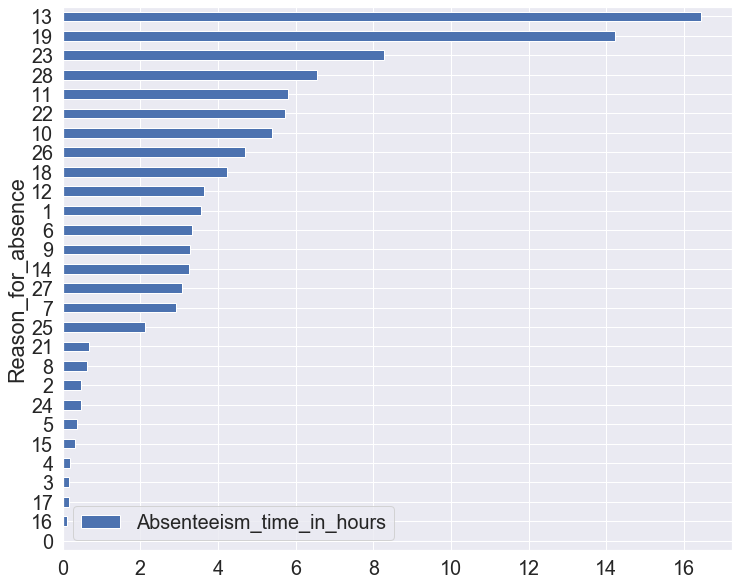

In [26]:
relationship('Reason_for_absence','Absenteeism_time_in_hours')

Top 5 categories in order of Absenteeism_time_in_hours are:

1. Category 13:Diseases of the musculoskeletal system and connective tissue - 16.43 % of total time
2. Category 19:Injury, poisoning and certain other consequences of external causes - 14.22 % of total time
3. Category 23:medical consultation - 11.17 % of total time
4. Category 28:Dental consultation - 6.53 % 0f total time

    
Conclusions & possible remedies:
    
1. Musculoskeletal system disease is the major reason of absentism. Bad working posture & high workload are possible reasons for the high incidence of musculoskeletal disease. Company should conduct a study on the working postures of people and go for more ergonomic workplace design. Company should try to optimize workload keeping in mind occupational health of working people.
2. Injury incidence may be reduced by creating proper ergonomic working setup.
3. Medical consultation may be brought down by optimizing workloads. 
4. Dental consultation time may be reduced by informing employees of the dental health guidelines so that they can take better care of their teeth.



#### 2. 'Month_of_absence' Vs. 'Absenteeism_time_in_hours'

    Month_of_absence  Absenteeism_time_in_hours
0                  0                   0.000000
1                  1                   4.332553
8                  8                   5.620609
9                  9                   5.698673
2                  2                   5.737705
10                10                   6.811085
5                  5                   7.806401
6                  6                   8.021077
12                12                   8.079625
11                11                   9.231069
4                  4                   9.406714
7                  7                  14.324746
3                  3                  14.929742


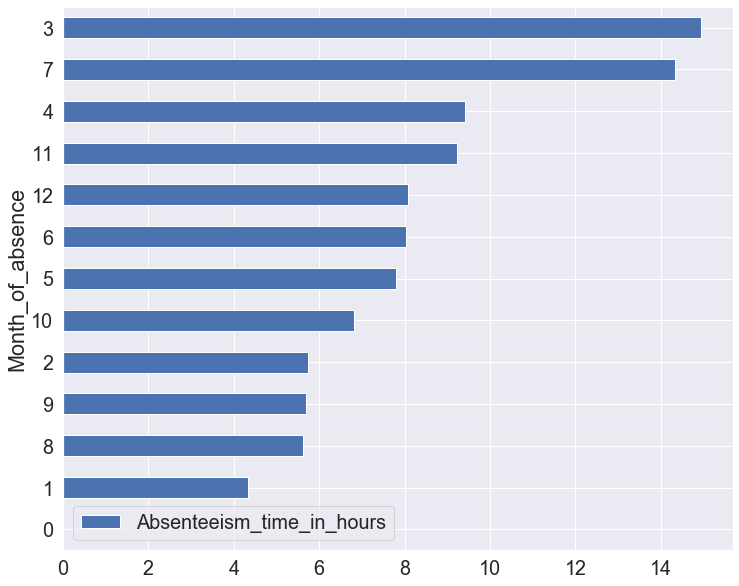

In [27]:
relationship('Month_of_absence','Absenteeism_time_in_hours')

Top 3 months in order of Absenteeism.time.in.hours are:

1. Month 3:March - 14.92 % of total time
2. Month 7:July - 14.32 % of total time
3. Month 4:April - 9.40 % of total time


#### 3. 'Day_of_the_week' Vs. 'Absenteeism_time_in_hours'

   Day_of_the_week  Absenteeism_time_in_hours
3                5                  10.792350
4                6                  14.402810
2                4                  21.760343
1                3                  23.985168
0                2                  29.059329


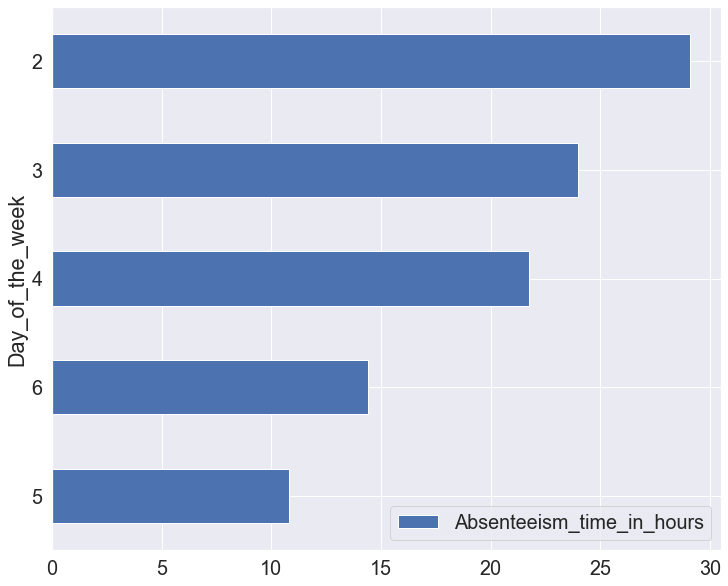

In [28]:
relationship('Day_of_the_week','Absenteeism_time_in_hours')

Top 3 days in order of Absenteeism_time_in_hours time are:

1. Day 2:Monday - 29.05 % of total time
2. Day 3:Tuesday - 23.98 % of total time
3. Day 4:Wednesday - 21.76 % of total time


For features such as "Education", "Son","Pet","Social_smoker","Social_drinker" which are not distributed evenly, we get the absolute value per person.

In [29]:
def relation_abs_pper(a,b):
    df = absentism_data.groupby(a)[b].agg(['sum','count']).reset_index()
    df['abs_per_person'] = df['sum'] / df['count']
    print(df)
    return df.plot.bar(x=a,y='abs_per_person',figsize=(16,12), rot=0)

#### 4. 'Education' Vs. 'Absenteeism_time_in_hours'

   Education   sum  count  abs_per_person
0          1  4393    611        7.189853
1          2   294     46        6.391304
2          3   416     79        5.265823
3          4    21      4        5.250000


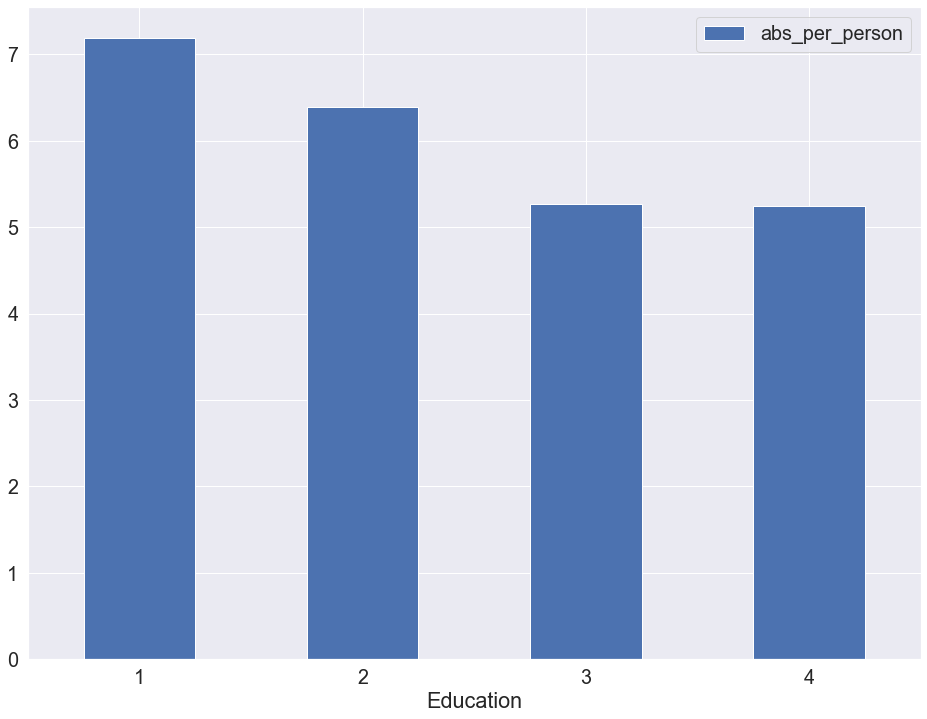

In [30]:
relation_abs_pper('Education','Absenteeism_time_in_hours')

Employees belonging to 1 category in Education are contributing the highest 7.92% absentism compared to other categories. 


#### 5.'Son' Vs 'Absenteeism_time_in_hours'

   Son   sum  count  abs_per_person
0    0  1605    298        5.385906
1    1  1381    229        6.030568
2    2  1649    156       10.570513
3    3   183     15       12.200000
4    4   306     42        7.285714


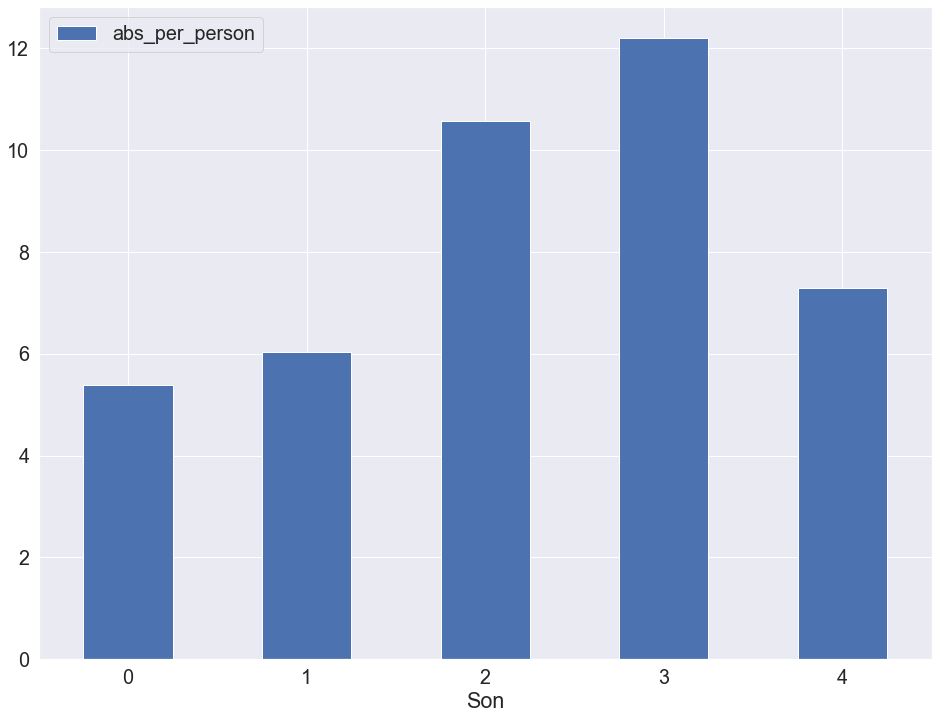

In [31]:
relation_abs_pper('Son','Absenteeism_time_in_hours')


Top 3 categories in order of Absenteeism.time.in.hours are:

1. Category 3:Three sons - 12.20 % of total time
2. Category 2:Two sons - 10.57 % of total time
3. Category 4:Four sons - 7.28 % of total time
    

Employees having  sons > 2 are mostly absent.



#### 6.'Pet' Vs 'Absenteeism_time_in_hours'

   Pet   sum  count  abs_per_person
0    0  3141    460        6.828261
1    1  1242    138        9.000000
2    2   456     96        4.750000
3    4   226     32        7.062500
4    5    25      6        4.166667
5    8    34      8        4.250000


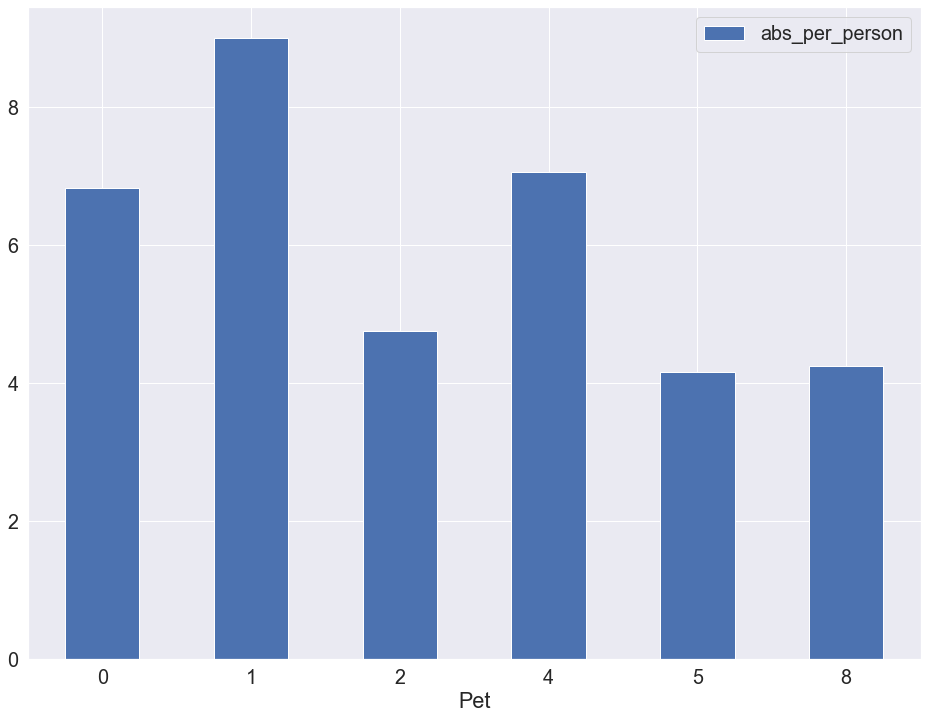

In [32]:
relation_abs_pper('Pet','Absenteeism_time_in_hours')


Top 3 categories in order of Absenteeism.time.in.hours are:

1. Category 1:One pet - 9.00 % of total time
2. Category 3:Three pet - 7.06 % of total time
3. Category 0:No pets - 6.82 % of total time

We can see that employees with more pets are less absent to office as compared to other employees. From this we can infer that, pets make employees happy and that is the reason the absentism is less among them.

#### 7.'Social drinker' Vs 'Absenteeism_time_in_hours'

   Social_drinker   sum  count  abs_per_person
0               0  1898    320        5.931250
1               1  3226    420        7.680952


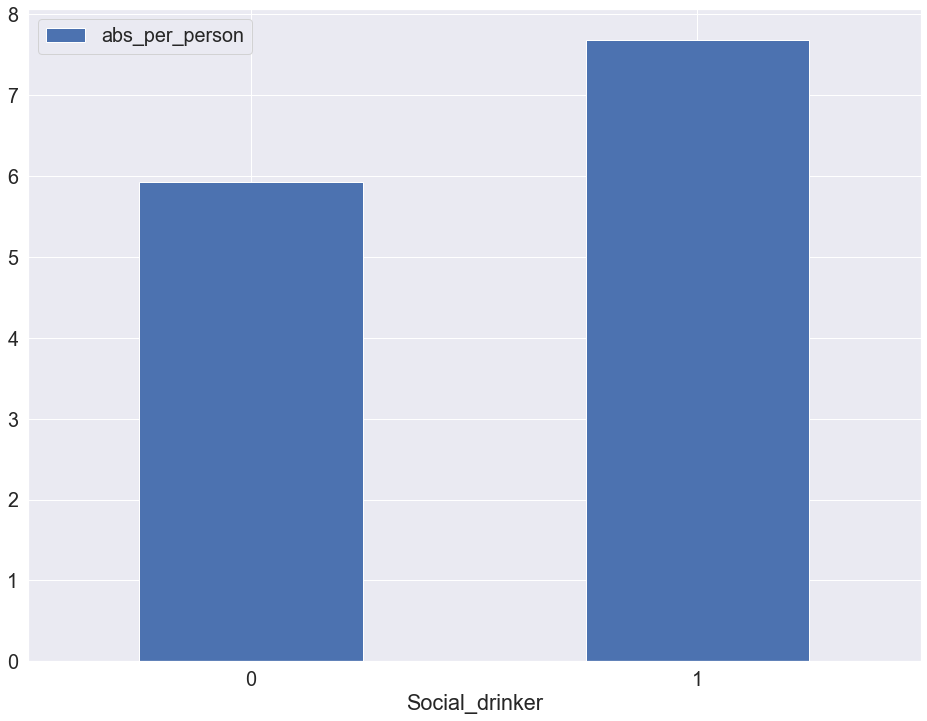

In [33]:
relation_abs_pper('Social_drinker','Absenteeism_time_in_hours')

Employees who are Social Drinker are absent mostly.

#### 8.'Social_smoker' Vs 'Absenteeism_time_in_hours'

   Social_smoker   sum  count  abs_per_person
0              0  4773    686        6.957726
1              1   351     54        6.500000


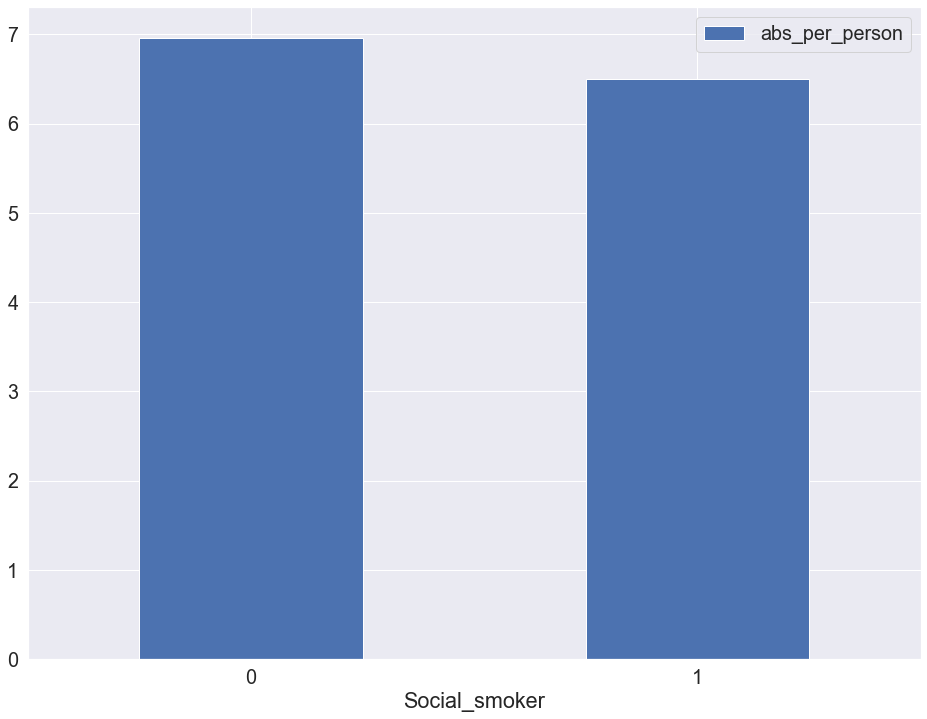

In [34]:
relation_abs_pper('Social_smoker','Absenteeism_time_in_hours')

Employees who don't smoke are slightly higher as compared to employees who smoke in terms of absenteeism.

#### 9. 'Social_Drinker' Vs 'Social_Smoker'

In [35]:
non_teetotaler = pd.crosstab(absentism_data['Social_drinker'],absentism_data['Social_smoker']).apply(lambda x: x/x.sum(),axis=0)

In [36]:
non_teetotaler

Social_smoker,0,1
Social_drinker,,
0,0.41691,0.62963
1,0.58309,0.37037


From this crosstab, we can infer that 58.3% of employees are alcoholics and 62.9% of employees only smoke. About 36% of employees both smoke and drink. 

#### Inferences from Categorical Variables

1. Reason_for_absence from office is mainly due to diseases of the musculoskeletal system and connective tissue.
2. March is the month where employees' are mostly absent in office.
3. Monday is the Day_of_the_week where employees' are mostly absent.
4. Most of the  Employees' have studied High School.
5. Employees' having 3 sons are mostly absent in office.
6. Employees' who have 2 pets are absent to office most of the time.
7. Employees who are addicted to alcohol aren't regular to office.
8. Those who smoke a lot are regular to office compared to employees' who don't smoke.
9. Comparing employees' being are teetotalers contribute to 42% of the data, while only smoking contributes 63% of employees' , only drinking 58.3% and both smoking and drinking contribute 37.03%.



### EDA on Continuous variables 

Inorder to convert a continuous variable to a categorical variable we bin the data and find out the range havin minimum and maximum value in it. Likewise, we are calculating min and max value for each continuous variable.

#### I. Continuous variable 'Service_time':-

In [37]:
print("Min Service_time of employees' :",min(absentism_data['Service_time']))
print("Max Service_time of employees' :",max(absentism_data['Service_time']))

Min Service_time of employees' : 1
Max Service_time of employees' : 29


#### Service_time bins

In [38]:
absentism_data['service_time_bins'] = pd.cut(absentism_data.Service_time,bins=[0,10,20,30],labels=['Low_service(0-10)','Medium_service(10-20)','High_service(20-30)'])

#### II. Consider continuous variable 'Weight':-

In [39]:
print("Min weight of employees' :",min(absentism_data['Weight']))
print("Max weight of employees' :",max(absentism_data['Weight']))

Min weight of employees' : 56
Max weight of employees' : 108


#### Weight_bins

In [40]:
absentism_data['weight_bins'] = pd.cut(absentism_data.Weight,bins=[55,75,95,115],labels=['Normal(55-75)','Overweight(75-95)','Obese(95-115)'])

#### III. Continuous variable 'Height':-

In [41]:
print("Min Height of employees' :",min(absentism_data['Height']))
print("Max weight of employees' :",max(absentism_data['Height']))

Min Height of employees' : 163
Max weight of employees' : 196


#### Height_bins

In [42]:
absentism_data['height_bins'] = pd.cut(absentism_data.Height,bins=[160,170,180,190,200],labels=['Normal(160-170)','Tall(170-180)','Very Tall(180-190)','Very Very Tall(190-200)'])

#### IV. Continuous variable 'Body_mass_index':-

In [43]:
print("Min Height of employees' :",min(absentism_data['Body_mass_index']))
print("Max weight of employees' :",max(absentism_data['Body_mass_index']))

Min Height of employees' : 19
Max weight of employees' : 38


#### BMI Bins

In [44]:
absentism_data['BMI_bins'] = pd.cut(absentism_data.Body_mass_index,bins=[15,25,35,45],labels=['Low(15-25)','Medium(25-35)','High(35-45)'])

#### IV. Continuous variable 'Age':-

In [45]:
print("Min Age of employees' :",min(absentism_data['Age']))
print("Max Age of employees' :",max(absentism_data['Age']))


Min Age of employees' : 27
Max Age of employees' : 58


#### Age_bins

In [46]:
absentism_data['Age_bins'] = pd.cut(absentism_data.Age,bins=[25,35,45,55,65],labels=['Adult(25-35)','Middle-Aged(35-45)','Old Middle Aged(45-55)','Senior Citizen(55-65)'])

#### V. Continuous variable 'Transportation_Expense':-

In [47]:
print("Min Transportation expense of employees' :",min(absentism_data['Transportation_expense']))
print("Max Transportation expense of employees' :",max(absentism_data['Transportation_expense']))

Min Transportation expense of employees' : 118
Max Transportation expense of employees' : 388


#### Expense_bins

In [48]:
absentism_data['Expense_bins'] = pd.cut(absentism_data.Transportation_expense,bins=[100,200,300,400],labels=['Low(100-200)','Medium(200-300)','High(300-400)'])

#### VI. Continuous variable 'Work_load_per_day':-

In [49]:
print("Min Work_load_Average_day of employees' :",min(absentism_data['Work_load_Average_day']))
print("Max Work_load_Average_day of employees' :",max(absentism_data['Work_load_Average_day']))

Min Work_load_Average_day of employees' : 205917
Max Work_load_Average_day of employees' : 378884


#### Work_load_bins

In [50]:
absentism_data['Work_load_bins'] = pd.cut(absentism_data.Work_load_Average_day,bins=[200000,250000,300000,350000,400000],labels=['Low(200K-250K)','Medium(250K-300K)','High(300K-350K)','Very high(350K-400K)'])

#### VII. Continuous variable 'Hit_target':-

In [51]:
print("Min Hit_target :",min(absentism_data['Hit_target']))
print("Max Hit_target :",max(absentism_data['Hit_target']))

Min Hit_target : 81
Max Hit_target : 100


#### Hit_target bins

In [52]:
absentism_data['hit_tgt_bins'] = pd.cut(absentism_data.Hit_target,bins=[80,85,90,95,100],labels=['Low_hit_tgt(80-85)','Medium_hit_tgt(85-90)','High_hit_tgt(90-95)','Very_high_hit_tgt(95-100)'])

#### VIII. Continuous variable 'Distance_from_Residence_to_Work':-

In [53]:
print("Min Distance_from_Residence_to_Work :",min(absentism_data['Distance_from_Residence_to_Work']))
print("Max Distance_from_Residence_to_Work :",max(absentism_data['Distance_from_Residence_to_Work']))

Min Distance_from_Residence_to_Work : 5
Max Distance_from_Residence_to_Work : 52


#### Distance_bins

In [54]:
absentism_data['distance_bins'] = pd.cut(absentism_data.Distance_from_Residence_to_Work,bins=[5,15,25,35,45,55],labels=['Short_dist(5-15)','Min_distance(15-25)','Normal_dist(25-35)','Long_dist(35-45)','Very_long_dist(45-55)'])

#### Let us compare the "weight_bins" Vs "Absenteeism_time_in_hours"

         weight_bins   sum  count  abs_per_person
0      Normal(55-75)  2282    333        6.852853
1  Overweight(75-95)  2411    346        6.968208
2      Obese(95-115)   431     61        7.065574


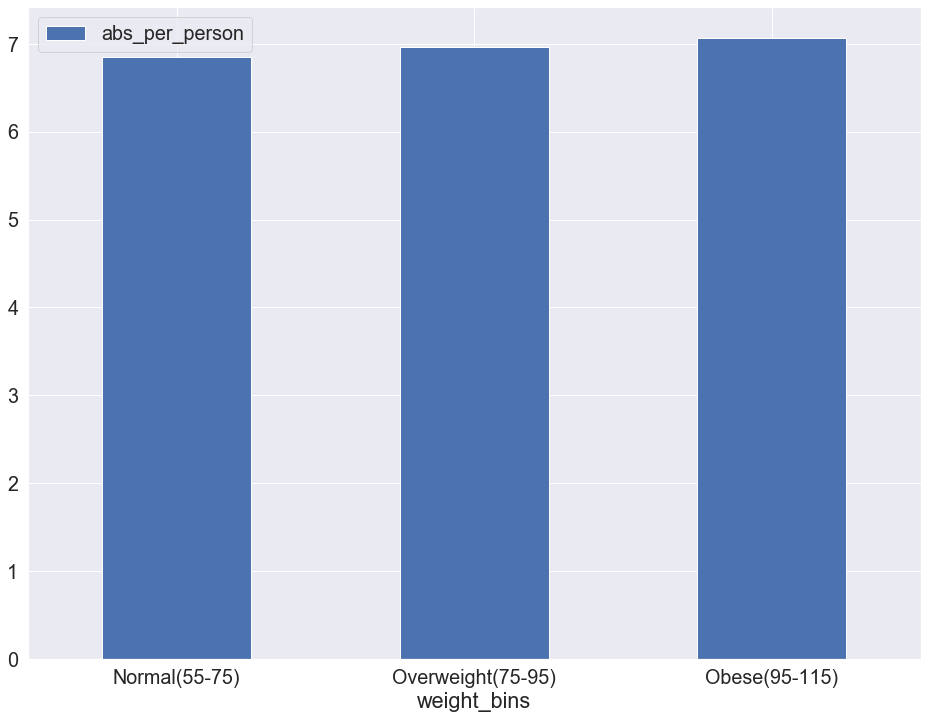

In [55]:
relation_abs_pper('weight_bins','Absenteeism_time_in_hours')

Employees who are "Obese" are mostly absent to office.

#### IX. Relationship between 'Service_time' Vs 'Absenteeism_time_in_hours'

       service_time_bins   sum  count  abs_per_person
0      Low_service(0-10)  1414    255        5.545098
1  Medium_service(10-20)  3678    478        7.694561
2    High_service(20-30)    32      7        4.571429


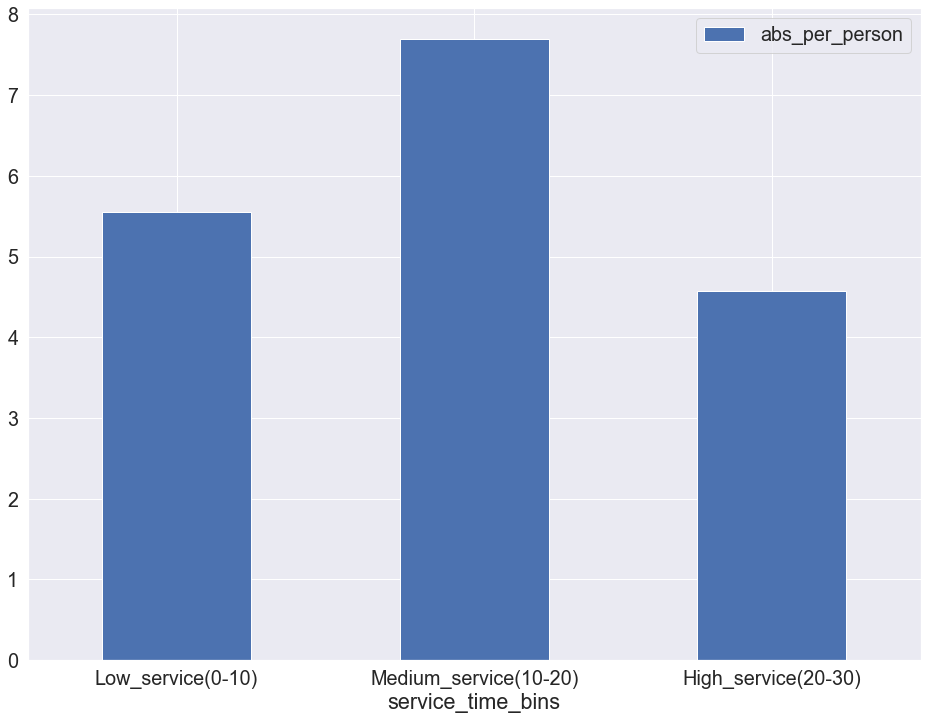

In [56]:
relation_abs_pper('service_time_bins','Absenteeism_time_in_hours')

The employees having medium service time have most absent time in hours.

#### X. Relationship of 'Age' Vs 'Absenteeism_time_in_hours'

                 Age_bins   sum  count  abs_per_person
0            Adult(25-35)  2241    292        7.674658
1      Middle-Aged(35-45)  2164    365        5.928767
2  Old Middle Aged(45-55)   457     75        6.093333
3   Senior Citizen(55-65)   262      8       32.750000


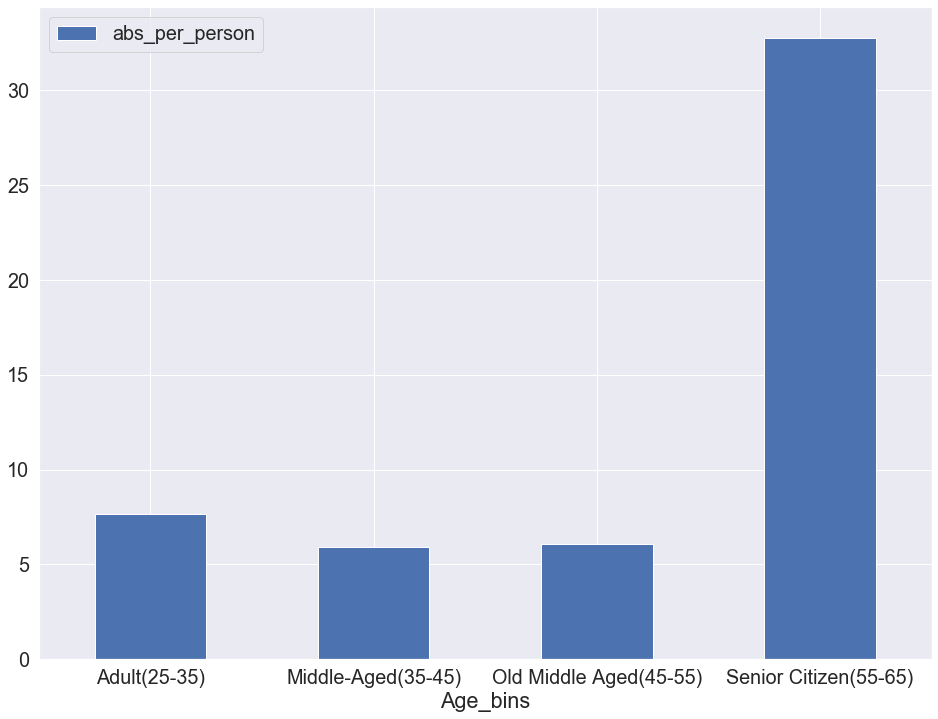

In [57]:
relation_abs_pper('Age_bins','Absenteeism_time_in_hours')

Employees who are Senior Citizens are mostly absent to office.

#### XI. Relationship between 'Transportation_Expense' and 'Absenteeism_Time_In_Hours'

      Expense_bins   sum  count  abs_per_person
0     Low(100-200)  2138    323        6.619195
1  Medium(200-300)  2443    351        6.960114
2    High(300-400)   543     66        8.227273


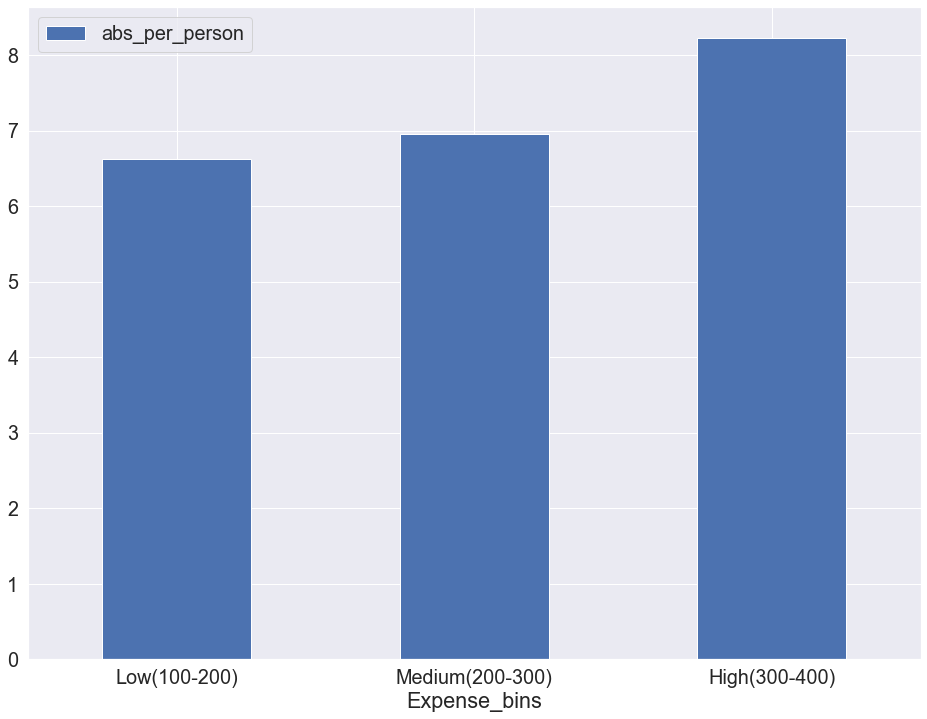

In [58]:
relation_abs_pper('Expense_bins','Absenteeism_time_in_hours')

Employees incurring High Transportation Expense are mostly absent to office.

#### XII. Relationship between 'Distance_from_Residence_to_Work' and 'Absenteeism_time_in_hours'

C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


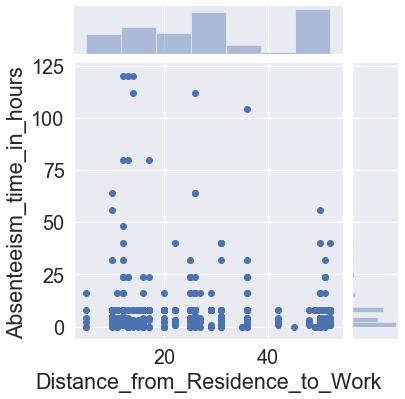

In [59]:
sns.jointplot(x='Distance_from_Residence_to_Work',y='Absenteeism_time_in_hours',data=absentism_data)

This shows that hours of absence has some correlation with Distance from residence to work.

#### XIII. Relationship between 'Work_load_Average_day' and 'Absenteeism_time_to_hours'

         Work_load_bins   sum  count  abs_per_person
0        Low(200K-250K)  1787    255        7.007843
1     Medium(250K-300K)  2110    318        6.635220
2       High(300K-350K)   945    135        7.000000
3  Very high(350K-400K)   282     32        8.812500


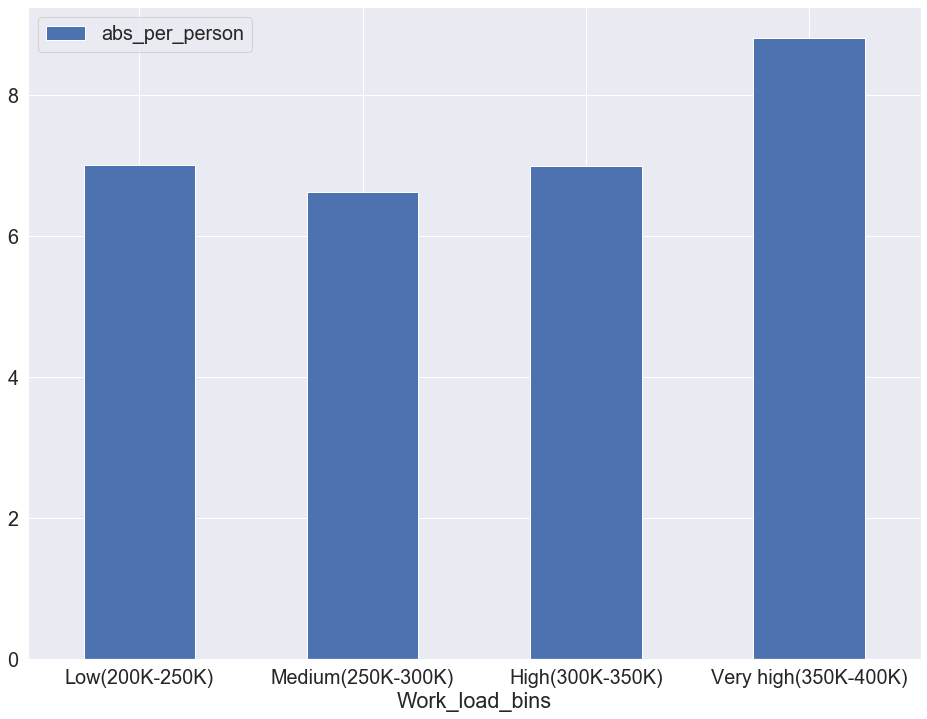

In [60]:
relation_abs_pper('Work_load_bins','Absenteeism_time_in_hours')

From the above figure, we can infer that Employees having Very high, high work_load/day are mostly absent . Also , we can see that employees having low work_load/day are also mostly absent. Maybe it can be employees maybe bored with the low work assigned to them, so they are mostly absent. While the Medium work_load employees are regular to office.


#### XIV. Relationship between 'Hit_target' and 'Absenteeism_time_in_hours'

                hit_tgt_bins   sum  count  abs_per_person
0         Low_hit_tgt(80-85)   163     19        8.578947
1      Medium_hit_tgt(85-90)   217     40        5.425000
2        High_hit_tgt(90-95)  2213    338        6.547337
3  Very_high_hit_tgt(95-100)  2531    343        7.379009


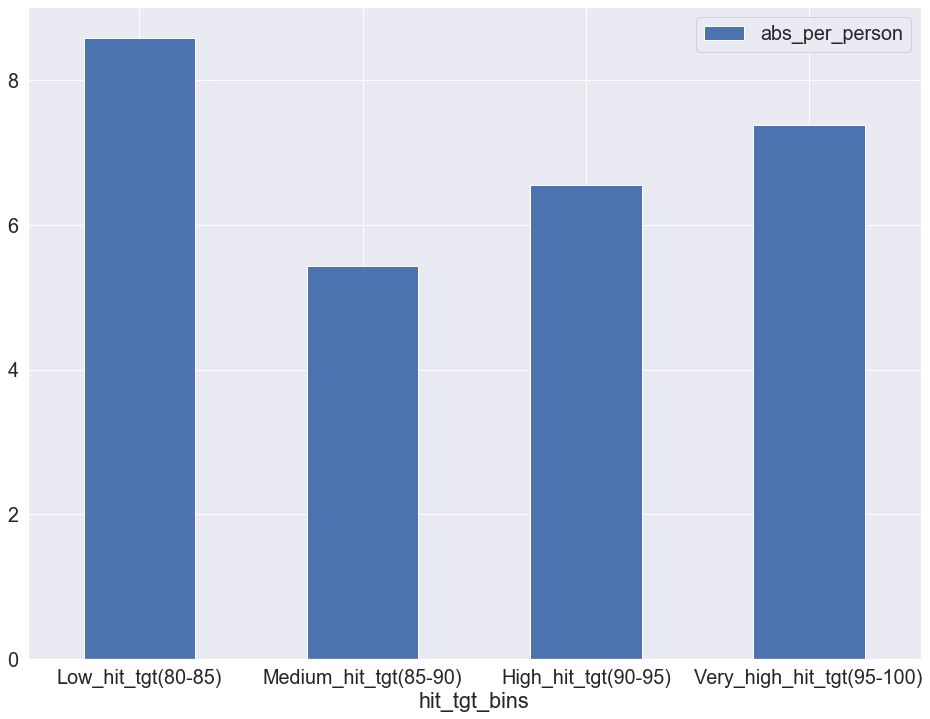

In [61]:
relation_abs_pper('hit_tgt_bins','Absenteeism_time_in_hours')

Employees you fall under "Very_high_hit_tgt" category are mostly absent followed by "high_hit_tgt" and "low_hit_tgt".

#### XV. Relationship between 'Age' and 'Absenteeism_time_in_hours' based on 'Day_of_the_week'

C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


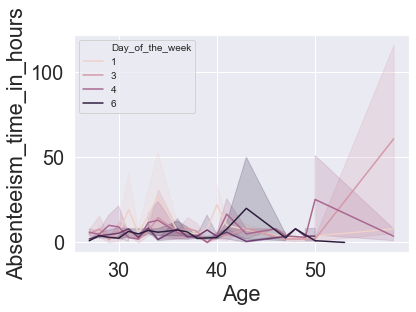

<Figure size 864x864 with 0 Axes>

In [121]:
sns.lineplot(x='Age',y='Absenteeism_time_in_hours',hue='Day_of_the_week', markers=True, data=absentism_data)
plt.legend(loc=2, prop={'size': 10})
plt.figure(figsize=(12,12))
plt.show()

From above graph,we see that along with 'Age' Day 6 is correlated. So most of the employees are absent on day 6 of the week i.e Friday.

#### Inferences from the EDA of continous variables:-

1. The employees' who are Obese are mostly absent to office.
2. Majority of the employees who range in the medium service time(10-20) are absent.
3. Senior Citizens are mostly absent to office.
4. Employees' having 'High Transport Expense' are mostly absent in work.
5. Employees' whose residence is farther from Office are absent in office.
6. Employees' having Very high work load average day are absent in time in hours.
7. Those who have 'Low hit target' are absent to office in time in hours.
8. Also, we can infer that Employees are mostly absent on Day 6-Friday at work.
9. While comparing 'Transportation_expense' with that of 'Distance_from_residence_to_work' , employees' having farther distance have more expense, shorter distance have less expense and medium distance have min. expense.

Note :- The Columns 'Seasons','Reason_of_absence','Son','Education','Pet' have the p-values (< 0.05) which reject the null hypothesis. We can drop these columns as well.

### Model Building

Considering only the columns which are used for training the model, instead of using all the features.

In [63]:
absentism_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 30 columns):
ID                                 740 non-null int64
Reason_for_absence                 740 non-null int64
Month_of_absence                   740 non-null int64
Day_of_the_week                    740 non-null int64
Seasons                            740 non-null int64
Transportation_expense             740 non-null int64
Distance_from_Residence_to_Work    740 non-null int64
Service_time                       740 non-null int64
Age                                740 non-null int64
Work_load_Average_day              740 non-null int64
Hit_target                         740 non-null int64
Disciplinary_failure               740 non-null int64
Education                          740 non-null int64
Son                                740 non-null int64
Social_drinker                     740 non-null int64
Social_smoker                      740 non-null int64
Pet                            

In [64]:
# Considering the features which are required and dropping the other cols
absentism_data = absentism_data.drop(['distance_bins','hit_tgt_bins','Work_load_bins','Expense_bins','Age_bins','BMI_bins','height_bins','weight_bins','service_time_bins','ID','Disciplinary_failure'],axis=1)

In [65]:
cols = ['Reason_for_absence','Month_of_absence','Seasons','Day_of_the_week','Transportation_expense','Distance_from_Residence_to_Work','Service_time','Age','Work_load_Average_day','Hit_target','Education','Son','Social_drinker','Social_smoker','Pet','Body_mass_index','Absenteeism_time_in_hours']

In [66]:
final_df = absentism[cols]

In [67]:
final_df.head()

,Reason_for_absence,Month_of_absence,Seasons,Day_of_the_week,Transportation_expense,Distance_from_Residence_to_Work,Service_time,Age,Work_load_Average_day,Hit_target,Education,Son,Social_drinker,Social_smoker,Pet,Body_mass_index,Absenteeism_time_in_hours
0,26,7,1,3,289,36,13,33,239554,97,1,2,1,0,1,30,4
2,23,7,1,4,179,51,18,38,239554,97,1,0,1,0,0,31,2
3,7,7,1,5,279,5,14,39,239554,97,1,2,1,1,0,24,4
4,23,7,1,5,289,36,13,33,239554,97,1,2,1,0,1,30,2
5,23,7,1,6,179,51,18,38,239554,97,1,0,1,0,0,31,2


In [68]:
final_df.columns

Index(['Reason_for_absence', 'Month_of_absence', 'Seasons', 'Day_of_the_week',
       'Transportation_expense', 'Distance_from_Residence_to_Work',
       'Service_time', 'Age', 'Work_load_Average_day', 'Hit_target',
       'Education', 'Son', 'Social_drinker', 'Social_smoker', 'Pet',
       'Body_mass_index', 'Absenteeism_time_in_hours'],
      dtype='object')

We see that the values are in different formats, let us bring it to a same scale by applying the Scaling Techniques.

#### 1. Scaling data using "StandardScaler"

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\preprocessing\data.py:625: DataConversionWarning: Data with input dtype int64 were all converted to float64 by StandardScaler.
  return self.partial_fit(X, y)
C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\base.py:462: DataConversionWarning: Data with input dtype int64 were all converted to float64 by StandardScaler.
  return self.fit(X, **fit_params).transform(X)
C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


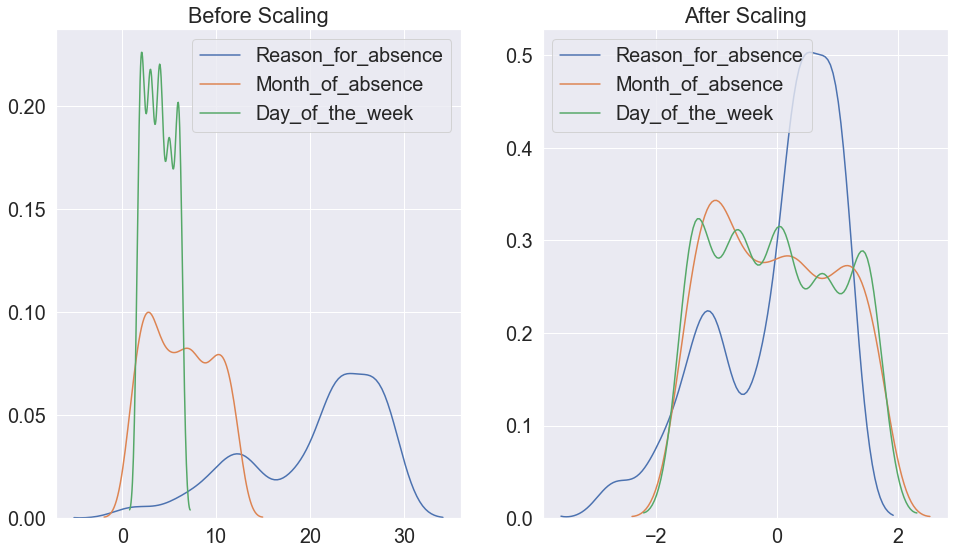

In [69]:
from sklearn.preprocessing import StandardScaler
from IPython.display import display

scaler = StandardScaler()
scaled_df = scaler.fit_transform(final_df)
scaled_df = pd.DataFrame(scaled_df, columns = final_df.columns)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(16,9))

ax1.set_title("Before Scaling")
sns.kdeplot(final_df['Reason_for_absence'], ax=ax1)
sns.kdeplot(final_df['Month_of_absence'], ax=ax1)
sns.kdeplot(final_df['Day_of_the_week'], ax=ax1)
ax1.legend(loc="upper right")

ax2.set_title("After Scaling")
sns.kdeplot(scaled_df['Reason_for_absence'], ax=ax2)
sns.kdeplot(scaled_df['Month_of_absence'], ax=ax2)
sns.kdeplot(scaled_df['Day_of_the_week'], ax=ax2)
ax2.legend(loc="upper left")
plt.show()

#### 2. Scaling data using "MinMaxScaler"

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\preprocessing\data.py:323: DataConversionWarning: Data with input dtype int64 were all converted to float64 by MinMaxScaler.
  return self.partial_fit(X, y)
C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval
No handles with labels found to put in legend.


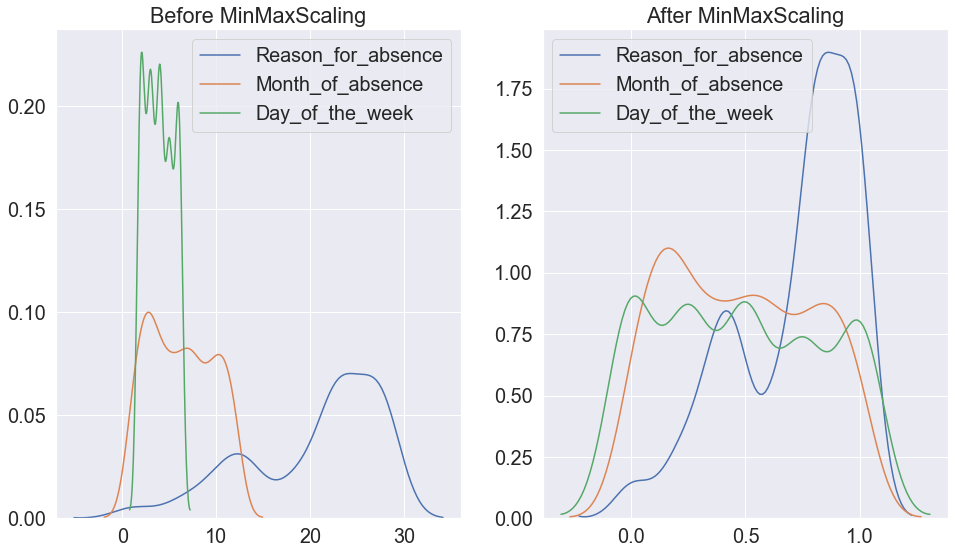

In [70]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()
minmax_df = min_max_scaler.fit_transform(final_df)
minmax_df = pd.DataFrame(minmax_df, columns = final_df.columns)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(16,9))

ax1.set_title("Before MinMaxScaling")
sns.kdeplot(final_df['Reason_for_absence'], ax=ax1)
sns.kdeplot(final_df['Month_of_absence'], ax=ax1)
sns.kdeplot(final_df['Day_of_the_week'], ax=ax1)
plt.legend(loc='upper right')

ax2.set_title("After MinMaxScaling")
sns.kdeplot(minmax_df['Reason_for_absence'], ax=ax2)
sns.kdeplot(minmax_df['Month_of_absence'], ax=ax2)
sns.kdeplot(minmax_df['Day_of_the_week'], ax=ax2)
plt.legend(loc='upper left')
plt.show()

After applying the scaling technique to the model. Let us now seperate the features from the target, by using X and Y dataframes respectively.

In [71]:
Y = scaled_df["Absenteeism_time_in_hours"]

In [72]:
X = scaled_df.iloc[:,:16]

#### Applying Statsmodel

In [73]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [74]:
X_constant = sm.add_constant(X)

C:\Users\Dad\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:2223: FutureWarning: Method .ptp is deprecated and will be removed in a future version. Use numpy.ptp instead.
  return ptp(axis=axis, out=out, **kwargs)


add_constant adds a column of ones to an array

In [75]:
model = sm.OLS(Y,X_constant)
lin_reg = model.fit()

In [76]:
lin_reg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                OLS Regression Results                               
=====================================================================================
Dep. Variable:     Absenteeism_time_in_hours   R-squared:                       0.144
Model:                                   OLS   Adj. R-squared:                  0.124
Method:                        Least Squares   F-statistic:                     7.130
Date:                       Tue, 25 Jun 2019   Prob (F-statistic):           2.04e-15
Time:                               18:58:35   Log-Likelihood:                -933.53
No. Observations:                        696   AIC:                             1901.
Df Residuals:                            679   BIC:                             1978.
Df Model:                                 16                                         
Covariance Type:                   nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                           -5.204e-17      0.036  -1.47e-15      1.000      -0.070       0.070
Reason_for_absence                 -0.2840      0.037     -7.576      0.000      -0.358      -0.210
Month_of_absence                    0.0243      0.048      0.510      0.610      -0.069       0.118
Seasons                            -0.0082      0.041     -0.199      0.843      -0.090       0.073
Day_of_the_week                    -0.1005      0.037     -2.715      0.007      -0.173      -0.028
Transportation_expense             -0.0092      0.047     -0.198      0.843      -0.101       0.082
Distance_from_Residence_to_Work    -0.1100      0.049     -2.245      0.025      -0.206      -0.014
Service_time                        0.0226      0.065      0.345      0.730      -0.106       0.151
Age                                 0.0606      0.055      1.100      0.272      -0.048       0.169
Work_load_Average_day              -0.0186      0.040     -0.470      0.639      -0.097       0.059
Hit_target                          0.0393      0.042      0.938      0.349      -0.043       0.122
Education                          -0.0572      0.043     -1.333      0.183      -0.142       0.027
Son                                 0.0924      0.042      2.190      0.029       0.010       0.175
Social_drinker                      0.1348      0.048      2.805      0.005       0.040       0.229
Social_smoker                      -0.0522      0.039     -1.340      0.181      -0.129       0.024
Pet                                 0.0134      0.047      0.287      0.774      -0.078       0.105
Body_mass_index                    -0.1040      0.050     -2.098      0.036      -0.201      -0.007
==============================================================================
Omnibus:                      743.501   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            35524.691
Skew:                           5.116   Prob(JB):                         0.00
Kurtosis:                      36.471   Cond. No.                         3.98
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [77]:
print(lin_reg.predict(X_constant[:10]))

0   -0.025416
1   -0.203075
2    0.809321
3   -0.046982
4   -0.343667
5   -0.283063
6    0.133110
7    0.647537
8   -0.058563
9    1.287147
dtype: float64


In [78]:
# Let's try using the r2_score to see the importance of features
from sklearn.metrics import r2_score
print(r2_score(Y, lin_reg.predict(X_constant)))

0.1438501034027283


The R2 score that we got above is 0.1438 and now this will serve as my base number. If the removal of a feature changes the R2 score significantly then that feature can be termed as an important feature.

In [79]:
# Without Day_of_the_week
lin_reg = smf.ols(formula = 'Y ~ Reason_for_absence + Month_of_absence + Seasons + Transportation_expense + Distance_from_Residence_to_Work + Service_time + Age + Work_load_Average_day + Hit_target + Education + Son + Social_drinker + Social_smoker + Pet + Body_mass_index ', data = X)
base = lin_reg.fit()
print(r2_score(Y, base.predict(X)))

0.1345533788117731


In [80]:
# Without Age
lin_reg = smf.ols(formula = 'Y ~ Reason_for_absence + Month_of_absence + Seasons + Day_of_the_week + Transportation_expense + Distance_from_Residence_to_Work + Service_time + Work_load_Average_day + Hit_target + Education + Son + Social_drinker + Social_smoker + Pet + Body_mass_index ', data = X)
base = lin_reg.fit()
print(r2_score(Y, base.predict(X)))

0.14232412205043277


Inferences :-
Removal of 'Day_of_the_week' feature has caused some change by reducing the score to 0.1345. However, removal of 'Age' column didn't cause any major difference as the score remained 0.1423. 

#### Splitting data into "train/test"

In [81]:
from sklearn.model_selection import train_test_split

In [82]:
X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size=0.25, random_state=0)

#### Linear Regression using scikit-learn

In [83]:
df_param = pd.DataFrame()

In [84]:
# import model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [85]:
# instantiate
linreg = LinearRegression()
linreg.fit(X_train,Y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None,
         normalize=False)

In [86]:
print('Intercept coefficient :',linreg.intercept_)
df_param['Linear_Regression'] = linreg.coef_

Intercept coefficient : 0.0004984946267147699


In [87]:
y_pred = linreg.predict(X_test)

In [88]:
print("Mean Squared Error",mean_squared_error(Y_test,y_pred))

Mean Squared Error 0.6163067565832723


In [89]:
print("Residual sum of squares: %.2f"%np.mean((linreg.predict(X_test) - Y_test) ** 2))

Residual sum of squares: 0.62


#### Implementing through Ridge and Lasso Regression

In [90]:
# Ridge
from sklearn.linear_model import Ridge

l_ridge = Ridge(alpha=0.5)
l_ridge.fit(X_train,Y_train)


Ridge(alpha=0.5, copy_X=True, fit_intercept=True, max_iter=None,
   normalize=False, random_state=None, solver='auto', tol=0.001)

In [91]:
print('Intercept Coefficient : ',l_ridge.intercept_)
df_param['Ridge'] = l_ridge.coef_

Intercept Coefficient :  0.00048801218253324667


In [92]:
y_ridge_pred = l_ridge.predict(X_test)

In [93]:
print("Mean Squared Error: ",mean_squared_error(Y_test, y_ridge_pred))
print("Residual sum of squares: %.2f"%np.mean((l_ridge.predict(X_test) - Y_test) ** 2))

Mean Squared Error:  0.6160362781556986
Residual sum of squares: 0.62


In [94]:
# Lasso
from sklearn.linear_model import Lasso

l_lasso = Lasso(alpha=0.1)
l_lasso.fit(X_train,Y_train)

Lasso(alpha=0.1, copy_X=True, fit_intercept=True, max_iter=1000,
   normalize=False, positive=False, precompute=False, random_state=None,
   selection='cyclic', tol=0.0001, warm_start=False)

In [95]:
print('Intercept Coefficient : ',l_lasso.intercept_)
df_param['Lasso'] = l_lasso.coef_

Intercept Coefficient :  0.002978043346431865


In [96]:
y_lasso_pred = l_lasso.predict(X_test)

In [97]:
print("Mean Squared Error: ",mean_squared_error(Y_test,y_lasso_pred))
print("Residual sum of squares: %.2f"%np.mean((l_lasso.predict(X_test) - Y_test) ** 2))

Mean Squared Error:  0.5798597529710285
Residual sum of squares: 0.58


### Parameter Tuning

In [98]:
from sklearn.model_selection import GridSearchCV

params = {'fit_intercept':[True,False], 'normalize':[True,False], 'copy_X':[True,False]}
grid = GridSearchCV(linreg, params , cv=None, scoring = 'neg_mean_squared_error')
grid.fit(X_train,Y_train)
print("Mean Squared Error: ",grid.best_score_)
print("Residual sum of squares: %.2f"%np.mean((grid.predict(X_test) - Y_test) ** 2))
l_reg = grid.best_estimator_
print(l_reg)

Mean Squared Error:  -1.0765114787094043
Residual sum of squares: 0.62
LinearRegression(copy_X=True, fit_intercept=False, n_jobs=None,
         normalize=True)


C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\model_selection\_split.py:2053: FutureWarning: You should specify a value for 'cv' instead of relying on the default value. The default value will change from 3 to 5 in version 0.22.
  warnings.warn(CV_WARNING, FutureWarning)


In [99]:
params={'alpha':[25,10,4,2,1.0,0.8,0.5,0.3,0.2,0.1,0.05,0.02,0.01]}
grid = GridSearchCV(l_ridge, params , cv=2, scoring = 'neg_mean_squared_error')
grid.fit(X_train,Y_train)
print("Mean Squared Error: ",grid.best_score_)
print("Residual sum of squares: %.2f"%np.mean((grid.predict(X_test) - Y_test) ** 2))
l_ridge = grid.best_estimator_
print(l_ridge)

Mean Squared Error:  -1.1051020270451377
Residual sum of squares: 0.61
Ridge(alpha=25, copy_X=True, fit_intercept=True, max_iter=None,
   normalize=False, random_state=None, solver='auto', tol=0.001)


In [100]:
params={'alpha':[25,10,4,2,1.0,0.8,0.5,0.3,0.2,0.1,0.05,0.02,0.01]}
grid = GridSearchCV(l_lasso, params, cv=2, scoring = 'neg_mean_squared_error')
grid.fit(X_train,Y_train)
print("Mean Squared Error: ",grid.best_score_)
print("Residual sum of squares: %.2f"%np.mean((grid.predict(X_test) - Y_test) ** 2))
l_lasso = grid.best_estimator_
print(l_lasso)

Mean Squared Error:  -1.053881442230234
Residual sum of squares: 0.58
Lasso(alpha=0.1, copy_X=True, fit_intercept=True, max_iter=1000,
   normalize=False, positive=False, precompute=False, random_state=None,
   selection='cyclic', tol=0.0001, warm_start=False)


### Comparing the Linear Regression Model

In [101]:
max_coef = max(df_param['Linear_Regression'])
df_param[df_param['Linear_Regression'] == max_coef]

,Linear_Regression,Ridge,Lasso
12,0.143041,0.142728,0.0


### Metrics

***
- Mean Absolute Error
    - Sum of the absolute differences between predictions and actual values.
- Mean Squared Error
- R-square score (Coefficient of determination)
    - Indication of the goodness of fit of a set of predictions to the actual values

In [116]:
from sklearn.model_selection import cross_validate
scoring = {'neg_mean_absolute_error',
           'neg_mean_squared_error',
           'r2'}

df_scores = pd.DataFrame()
for model in [linreg, l_ridge, l_lasso]:
    scores = cross_validate(linreg, X_train, Y_train, scoring=scoring, cv=5, return_train_score=True )
    score = []
    for key in scores.keys():
        score.append(scores[key].mean())
    df_scores[str(model)] = score
    df_scores['metric_params'] = scores.keys()
df_scores = df_scores.set_index('metric_params')

In [119]:
df_scores.columns = ["Linear_Reg","Ridge","Lasso"]

In [120]:
df_scores

,Linear_Reg,Ridge,Lasso
metric_params,,,
fit_time,0.004801,0.004001,0.004000
score_time,0.004798,0.005599,0.003199
test_r2,0.070418,0.070418,0.070418
train_r2,0.160578,0.160578,0.160578
test_neg_mean_absolute_error,-0.489746,-0.489746,-0.489746
train_neg_mean_absolute_error,-0.462477,-0.462477,-0.462477
test_neg_mean_squared_error,-1.029574,-1.029574,-1.029574
train_neg_mean_squared_error,-0.934534,-0.934534,-0.934534


#### Checking for homoscedasticity assumption

Homoscedasticity describes a situation in which the error term is the same across all values of the independent variables.

In [113]:
# Let us first get the predicted values
y_pred = linreg.predict(X_test)

In [114]:
# Residual values
resid = y_pred - Y_test

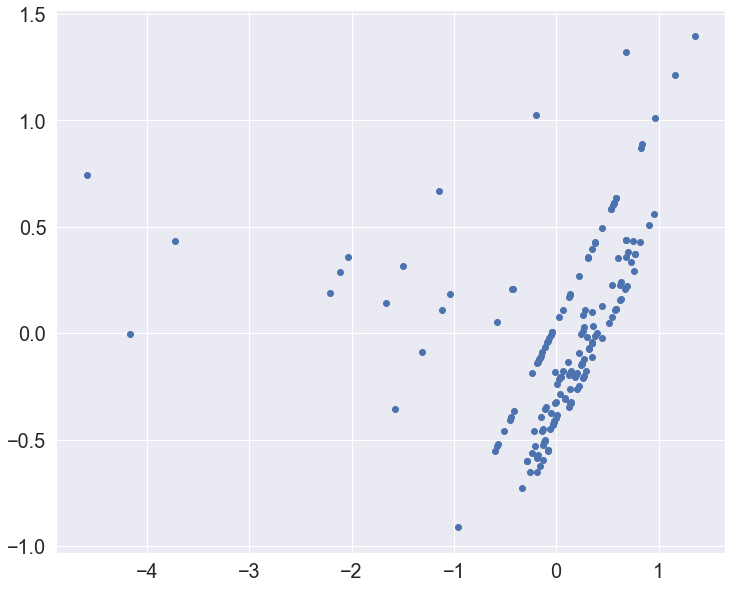

In [115]:
fig, ax = plt.subplots(figsize=(12,10))
_ = ax.scatter(resid, y_pred)

From the above graph, we are not able to observe any constant variance. Hence, it fails the homoscedasticity  assumption.